# Compositional design of a two-input transcriptional AND circuit

This notebook treats each candidate $D_i$ as a biological implementation, not
as a label for an arbitrarily selected asymptotic regime. Two characterized
Marionette sensors provide promoter activities $(\xi_1,\xi_2)$ in relative
promoter units (RPU). Lumped expression modules produce two binding partners,
which form a catalytic complex and generate one output transcription flux.

The model is
\[
\Sigma_1:\xi_1\mapsto Y_1,\qquad
\Sigma_2:\xi_2\mapsto Y_2,
\]
\[
Y_1+Y_2\rightleftharpoons C_3,
\qquad C_3\longrightarrow C_3+P,
\qquad y=\dot P=k_{\rm out}C_3.
\]
At quasi-steady binding,
\[
K C_3=(Y_{1,\rm tot}-C_3)(Y_{2,\rm tot}-C_3).
\]
The product-forming step is coarse grained: transcriptional resources are
implicit and neither input component is asserted to be chemically converted
into the reporter product.

In [14]:
import math
import os
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", str(Path.cwd() / ".matplotlib"))

PAPER_FIGURES_DIR = next(
    (
        base / "paper_ACC_2027" / "figs"
        for base in (Path.cwd(), *Path.cwd().parents)
        if (base / "paper_ACC_2027" / "figs").is_dir()
    ),
    None,
)
if PAPER_FIGURES_DIR is None:
    raise FileNotFoundError("Could not find paper_ACC_2027/figs")

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
import numpy as np
import pandas as pd

from compositional_regime_contracts import (
    CORES,
    DEFAULT_ON_THRESHOLD_NM_PER_MIN,
    DEFAULT_OFF_THRESHOLD_NM_PER_MIN,
    MARIONETTE_SENSORS,
    REDESIGNS,
    REDESIGN_PARAMETERS,
    complex_concentration,
    condition_flux_interval,
    infer_regime,
    make_candidate_designs,
    make_top_level_conditions,
    initial_flux_bounds,
    redesigned_condition_flux_interval,
    redesigned_flux_bounds,
    sensor_activity,
    summarize_candidate_envelopes,
    summarize_redesigned_envelopes,
    verify_condition,
    verify_redesigned_condition,
)

pd.set_option("display.max_colwidth", 80)
candidates = make_candidate_designs()

## Characterized sensor interfaces

The aTc and Cuma entries below are transcribed from the Marionette sensor table
used in the Pacti case study, based on Meyer *et al.* (2019). Their physical
inducer concentrations are different, but each sensor exposes the same circuit
interface: output-promoter activity in RPU. No coordinate normalization by an
operating point or kinetic constant is performed.

In [15]:
sensor_rows = []
for sensor in MARIONETTE_SENSORS.values():
    sensor_rows.append({
        "Sensor": sensor.name,
        "Promoter": sensor.promoter,
        "Regulator": sensor.regulator,
        "leak [RPU]": sensor.leak_rpu,
        "K [uM]": sensor.half_max_uM,
        "Hill n": sensor.hill_n,
        "measured max [RPU]": sensor.max_rpu,
        "validated linear max [RPU]": sensor.linear_max_rpu,
    })
sensor_table = pd.DataFrame(sensor_rows)
sensor_table

,Sensor,Promoter,Regulator,leak [RPU],K [uM],Hill n,measured max [RPU],validated linear max [RPU]
0,aTc,PTet*,TetR,0.0049,0.013,3.8,2.4,1.0
1,Cuma,PCymRC,CymRAM,0.0043,8.900,2.4,3.7,2.0


## Integration cores and initial design parameters

The three architectures use the effective affinities, promoter-to-component
gains, and output rates below as the fixed parameter values defining the
initial designs in the computational example.

In [16]:
core_rows = []
for core in CORES:
    core_rows.append({
        "Core": core.name,
        "Input 1": core.component_1,
        "Input 2": core.component_2,
        "Output promoter": core.output_promoter,
        "K [nM]": core.affinity_nM,
        "k_out [1/min]": core.output_rate_per_min,
        "g1 [nM/RPU]": core.gain_1_nM_per_rpu,
        "g2 [nM/RPU]": core.gain_2_nM_per_rpu,
        "center regime": core.nominal_regime,
    })
core_table = pd.DataFrame(core_rows)
display(core_table)



,Core,Input 1,Input 2,Output promoter,K [nM],k_out [1/min],g1 [nM/RPU],g2 [nM/RPU],center regime
0,HrpR/HrpS,HrpR,HrpS,PhrpL,250.0,1.2,4000.0,800.0,input 1 excess
1,split T7 RNAP,T7 RNAP N fragment,T7 RNAP C fragment,PT7,1200.0,10.0,500.0,700.0,affinity-dominated
2,InvF/SicA,InvF,SicA,PsicA,250.0,1.0,800.0,4000.0,input 2 excess


## Candidate designs

Each integration core is paired with both ordered assignments of aTc and Cuma.
Ordering changes the physical inducer-to-promoter map even when two candidates
have the same contract after the RPU interface. This is an intended example of
interface abstraction: downstream verification can be reused while the
physical sensor implementation changes.

In [17]:
design_rows = []
for candidate in candidates:
    design_rows.append({
        "Design": candidate.name,
        "Core": candidate.core.name,
        "Sensor -> input 1": f"{candidate.sensor_1.name} -> {candidate.core.component_1}",
        "Sensor -> input 2": f"{candidate.sensor_2.name} -> {candidate.core.component_2}",
        "Regime at xi=(0.5,0.5)": infer_regime(candidate, 0.5, 0.5),
    })
design_table = pd.DataFrame(design_rows)
design_table

,Design,Core,Sensor -> input 1,Sensor -> input 2,"Regime at xi=(0.5,0.5)"
0,D1,HrpR/HrpS,aTc -> HrpR,Cuma -> HrpS,input 1 excess
1,D2,HrpR/HrpS,Cuma -> HrpR,aTc -> HrpS,input 1 excess
2,D3,split T7 RNAP,aTc -> T7 RNAP N fragment,Cuma -> T7 RNAP C fragment,affinity-dominated
3,D4,split T7 RNAP,Cuma -> T7 RNAP N fragment,aTc -> T7 RNAP C fragment,affinity-dominated
4,D5,InvF/SicA,aTc -> InvF,Cuma -> SicA,input 2 excess
5,D6,InvF/SicA,Cuma -> InvF,aTc -> SicA,input 2 excess


## Top-level AND-gate specification

The desired AND behavior contains one ON region and two mixed OFF regions:
\[
(\xi_1,\xi_2)\in H\times H\Longrightarrow y\ge y_{\rm ON},
\]
\[
(\xi_1,\xi_2)\in L\times H\Longrightarrow y\le y_{\rm OFF},
\qquad
(\xi_1,\xi_2)\in H\times L\Longrightarrow y\le y_{\rm OFF}.
\]
By the monotonicity result developed for the model class, the LOW--LOW case is
already implied by either mixed OFF condition and is not introduced as a
separate contract mode.
The input regions are stated in promoter activity units. The ON region lies inside
the experimentally useful Marionette RPU range. The OFF interval begins near
the characterized leak floors and extends to 20% of the ON onset; the interval
from 0.07 to 0.35 RPU is deliberately left unconstrained. The
round exploratory flux targets impose a twofold output separation. In an
experimental design, these levels would be set from measured sensor variation
and the activation and burden limits of the downstream receiver.

In [18]:
conditions = make_top_level_conditions()
envelope_summary = summarize_candidate_envelopes(candidates, conditions)
condition_table = pd.DataFrame([
    {
        "Condition": condition.name,
        "xi1 [RPU]": condition.xi1_bounds,
        "xi2 [RPU]": condition.xi2_bounds,
        "Required flux": (
            f">= {condition.flux_threshold:.2f} nM/min"
            if condition.guarantee_kind == "lower"
            else f"<= {condition.flux_threshold:.2f} nM/min"
        ),
    }
    for condition in conditions
])
display(pd.DataFrame({
    "Core": envelope_summary["on_floors"].keys(),
    "worst-case ON floor [nM/min]": envelope_summary["on_floors"].values(),
    "worst-case OFF ceiling [nM/min]": envelope_summary["off_ceilings"].values(),
}))
display(condition_table)

,Core,worst-case ON floor [nM/min],worst-case OFF ceiling [nM/min]
0,HrpR/HrpS,276.816705,197.292246
1,split T7 RNAP,269.131593,101.834193
2,InvF/SicA,230.680587,164.410205


,Condition,xi1 [RPU],xi2 [RPU],Required flux
0,ON,"(0.35, 0.65)","(0.35, 0.65)",>= 120.00 nM/min
1,OFF-1,"(0.0055, 0.07)","(0.35, 0.65)",<= 60.00 nM/min
2,OFF-2,"(0.35, 0.65)","(0.0055, 0.07)",<= 60.00 nM/min


## Composition and formal checks

For each finite operating region, the catalytic-core contract uses the globally valid
bounds
\[
\frac{Y_1Y_2}{K+Y_1+Y_2}\le C_3
\le\min\left\{Y_1,Y_2,\frac{Y_1Y_2}{K}\right\}.
\]
Monotonic endpoint bounds tighten this contract over each region. The fixed
design parameters are used when composing the two lumped expression contracts
with the core contract. Upstream gain guarantees and downstream core
assumptions use the same closed boundaries exactly; no numerical padding is
introduced. A design implements the complete AND
specification only if it refines the ON, OFF-1, and OFF-2 contracts.

The top-level object is therefore the mode-indexed family
\[
\mathfrak C_{\rm spec}=\{\mathcal C_{\rm ON},
\mathcal C_{\rm OFF,1},\mathcal C_{\rm OFF,2}\},
\qquad
D\models\mathfrak C_{\rm spec}
\Longleftrightarrow
\bigwedge_q \mathcal C_D^q\preceq\mathcal C_{\rm spec}^q.
\]
An ordinary Pacti merge is not used: it would conjoin the mutually exclusive
mode assumptions instead of preserving the three conditional requirements.

In [19]:
verification_rows = []
verification = {}
for candidate in candidates:
    condition_results = {}
    for condition in conditions:
        result = verify_condition(candidate, condition)
        condition_results[condition.name] = result
    verification[candidate.name] = condition_results
    verification_rows.append({
        "Design": candidate.name,
        "Core": candidate.core.name,
        "Sensors (input 1, input 2)": f"({candidate.sensor_1.name}, {candidate.sensor_2.name})",
        "A_ON subset A_D": condition_results["ON"]["assumptions"],
        "G_D implies G_ON": condition_results["ON"]["guarantees"],
        "A_OFF,1 subset A_D": condition_results["OFF-1"]["assumptions"],
        "G_D implies G_OFF,1": condition_results["OFF-1"]["guarantees"],
        "A_OFF,2 subset A_D": condition_results["OFF-2"]["assumptions"],
        "G_D implies G_OFF,2": condition_results["OFF-2"]["guarantees"],
        "Full AND refinement": all(result["refines"] for result in condition_results.values()),
    })
verification_table = pd.DataFrame(verification_rows)
verification_table

,Design,Core,"Sensors (input 1, input 2)",A_ON subset A_D,G_D implies G_ON,"A_OFF,1 subset A_D","G_D implies G_OFF,1","A_OFF,2 subset A_D","G_D implies G_OFF,2",Full AND refinement
0,D1,HrpR/HrpS,"(aTc, Cuma)",False,True,False,False,False,False,False
1,D2,HrpR/HrpS,"(Cuma, aTc)",False,True,False,False,False,False,False
2,D3,split T7 RNAP,"(aTc, Cuma)",False,True,False,False,False,False,False
3,D4,split T7 RNAP,"(Cuma, aTc)",False,True,False,False,False,False,False
4,D5,InvF/SicA,"(aTc, Cuma)",False,True,False,True,False,False,False
5,D6,InvF/SicA,"(Cuma, aTc)",False,True,False,True,False,False,False


In [20]:
interval_rows = []
for candidate in candidates[::2]:
    row = {"Core": candidate.core.name}
    for condition in conditions:
        lo, hi = condition_flux_interval(
            candidate, condition.xi1_bounds, condition.xi2_bounds
        )
        row[condition.name] = f"[{lo:.1f}, {hi:.1f}]"
    interval_rows.append(row)
pd.DataFrame(interval_rows)

,Core,ON,OFF-1,OFF-2
0,HrpR/HrpS,"[276.8, 558.6]","[13.7, 197.3]","[4.5, 61.2]"
1,split T7 RNAP,"[269.1, 777.4]","[4.7, 94.8]","[4.9, 101.8]"
2,InvF/SicA,"[230.7, 465.5]","[3.7, 51.0]","[11.4, 164.4]"


### Initial design insight

At the fixed initial parameter values, none of the three cores satisfies all
three modes. HrpR/HrpS satisfies the ON requirement but exceeds both OFF
ceilings. Split T7 RNAP satisfies the ON requirement but exceeds both OFF
ceilings. InvF/SicA satisfies the ON and OFF-1 requirements but exceeds the
OFF-2 ceiling. The equality of each ordered sensor pair after the RPU interface
still shows what the abstraction provides; their required inducer
concentrations remain different in the sensor contracts.

## Contract-guided redesigns

The fixed ON/OFF specification remains unchanged. Each initial design is
evaluated at its stated parameter values, and each redesign updates the
mechanism-specific design parameter(s). The contract calculation determines
whether the resulting design satisfies all three modes.

1. **HrpR/HrpS:** treat the HrpV inhibitory level as a tunable regulation
   parameter. For the fixed specification, the feasible design
   interval is approximately $0.114$--$0.131\,\mu\mathrm{M}$; use
   $V_{\mathrm{eff}}=0.12\,\mu\mathrm{M}$.
2. **split T7 RNAP:** use the effective fragment-association parameter as the
   redesign variable. The full contract is feasible for approximately
   $K=2.286$--$3.165\,\mu\mathrm{M}$; use $K=3.0\,\mu\mathrm{M}$ to
   increase OFF-state margin while retaining the ON guarantee.
3. **InvF/SicA:** use the reduced SicA--SipC turnover model with the published
   $K_{YZ}=28\,\mathrm{nM}$, $k_Z=0.1\,\mathrm{min}^{-1}$, and degradation
   rates $\gamma_X=\gamma_{XY}=0.022$, $\gamma_Y=0.046$,
   $\gamma_Z=0.139$, and $\gamma_{YZ}=0.022\,\mathrm{min}^{-1}$.

The cells below compute the contract-feasible parameter windows for the first
two redesigns and then run the same mode-wise refinement checks for all three.

In [21]:
# Contract-feasible fixed-parameter redesign windows for the two direct QSS cores.
representative_by_core = {}
for candidate in candidates:
    representative_by_core.setdefault(candidate.core.name, candidate)

hrp = representative_by_core["HrpR/HrpS"].core
c_on = float(complex_concentration(
    hrp.gain_1_nM_per_rpu * 0.35,
    hrp.gain_2_nM_per_rpu * 0.35,
    hrp.affinity_nM,
))
c_off1 = float(complex_concentration(
    hrp.gain_1_nM_per_rpu * 0.07,
    hrp.gain_2_nM_per_rpu * 0.65,
    hrp.affinity_nM,
))
c_off2 = float(complex_concentration(
    hrp.gain_1_nM_per_rpu * 0.65,
    hrp.gain_2_nM_per_rpu * 0.07,
    hrp.affinity_nM,
))
hrpv_low = max(
    c_off1 - DEFAULT_OFF_THRESHOLD_NM_PER_MIN / hrp.output_rate_per_min,
    c_off2 - DEFAULT_OFF_THRESHOLD_NM_PER_MIN / hrp.output_rate_per_min,
    0.0,
)
hrpv_high = c_on - DEFAULT_ON_THRESHOLD_NM_PER_MIN / hrp.output_rate_per_min

split = representative_by_core["split T7 RNAP"].core
def affinity_at_complex(input_1_nM, input_2_nM, complex_nM):
    return ((input_1_nM - complex_nM) * (input_2_nM - complex_nM)) / complex_nM

c_on_req = DEFAULT_ON_THRESHOLD_NM_PER_MIN / split.output_rate_per_min
c_off_req = DEFAULT_OFF_THRESHOLD_NM_PER_MIN / split.output_rate_per_min
split_k_high = affinity_at_complex(
    split.gain_1_nM_per_rpu * 0.35,
    split.gain_2_nM_per_rpu * 0.35,
    c_on_req,
)
split_k_low = max(
    affinity_at_complex(
        split.gain_1_nM_per_rpu * 0.07,
        split.gain_2_nM_per_rpu * 0.65,
        c_off_req,
    ),
    affinity_at_complex(
        split.gain_1_nM_per_rpu * 0.65,
        split.gain_2_nM_per_rpu * 0.07,
        c_off_req,
    ),
)

pd.DataFrame([
    {
        "Core": "HrpR/HrpS",
        "design variable": "HrpV [nM]",
        "feasible low": hrpv_low,
        "feasible high": hrpv_high,
        "selected": REDESIGN_PARAMETERS["HrpR/HrpS"]["hrpv_nM"],
    },
    {
        "Core": "split T7 RNAP",
        "design variable": "effective K [nM]",
        "feasible low": split_k_low,
        "feasible high": split_k_high,
        "selected": REDESIGN_PARAMETERS["split T7 RNAP"]["affinity_nM"],
    },
])

,Core,design variable,feasible low,feasible high,selected
0,HrpR/HrpS,HrpV [nM],114.410205,130.680587,120.0
1,split T7 RNAP,effective K [nM],2286.166667,3164.916667,3000.0


In [22]:
redesign_rows = []
for core_name, redesign in REDESIGNS.items():
    params = REDESIGN_PARAMETERS[core_name]
    redesign_rows.append({
        "Core": core_name,
        "Redesign": redesign.label,
        "Mechanism": redesign.mechanism,
        "Selected redesign parameters": str(params),
        "Source": redesign.source,
    })
display(pd.DataFrame(redesign_rows))



,Core,Redesign,Mechanism,Selected redesign parameters,Source
0,HrpR/HrpS,tuned HrpV inhibition,hrpv_threshold,{'hrpv_nM': 120.0},"Jovanovic et al., Nature Communications 2011, doi:10.1038/ncomms1177; Wang e..."
1,split T7 RNAP,weakened zipper recruitment,synzip_affinity,{'affinity_nM': 3000.0},"Segall-Shapiro et al., Molecular Systems Biology 2014, doi:10.15252/msb.2014..."
2,InvF/SicA,SipC turnover and secretion,sipc_titration,"{'sink_affinity_nM': 28.0, 'gamma_x_per_min': 0.022, 'gamma_xy_per_min': 0.0...","Temme et al., Journal of Molecular Biology 2008, doi:10.1016/j.jmb.2007.12.044"


In [23]:
redesigned_envelope_summary = summarize_redesigned_envelopes(candidates, conditions)

redesigned_verification_rows = []
redesigned_verification = {}
for candidate in candidates:
    condition_results = {}
    for condition in conditions:
        result = verify_redesigned_condition(candidate, condition)
        condition_results[condition.name] = result
    redesigned_verification[candidate.name] = condition_results
    redesigned_verification_rows.append({
        "Design": candidate.name,
        "Core": candidate.core.name,
        "Redesign": REDESIGNS[candidate.core.name].label,
        "Sensors (input 1, input 2)": f"({candidate.sensor_1.name}, {candidate.sensor_2.name})",
        "ON": condition_results["ON"]["refines"],
        "OFF-1": condition_results["OFF-1"]["refines"],
        "OFF-2": condition_results["OFF-2"]["refines"],
        "Full AND refinement": all(result["refines"] for result in condition_results.values()),
    })
redesigned_verification_table = pd.DataFrame(redesigned_verification_rows)
display(redesigned_verification_table)

redesigned_interval_rows = []
for candidate in candidates[::2]:
    row = {
        "Core": candidate.core.name,
        "Redesign": REDESIGNS[candidate.core.name].label,
    }
    for condition in conditions:
        lo, hi = redesigned_condition_flux_interval(
            candidate, condition.xi1_bounds, condition.xi2_bounds
        )
        row[condition.name] = f"[{lo:.3g}, {hi:.3g}]"
    redesigned_interval_rows.append(row)
pd.DataFrame(redesigned_interval_rows)

,Design,Core,Redesign,"Sensors (input 1, input 2)",ON,OFF-1,OFF-2,Full AND refinement
0,D1,HrpR/HrpS,tuned HrpV inhibition,"(aTc, Cuma)",False,False,False,False
1,D2,HrpR/HrpS,tuned HrpV inhibition,"(Cuma, aTc)",False,False,False,False
2,D3,split T7 RNAP,weakened zipper recruitment,"(aTc, Cuma)",False,False,False,False
3,D4,split T7 RNAP,weakened zipper recruitment,"(Cuma, aTc)",False,False,False,False
4,D5,InvF/SicA,SipC turnover and secretion,"(aTc, Cuma)",False,False,False,False
5,D6,InvF/SicA,SipC turnover and secretion,"(Cuma, aTc)",False,False,False,False


,Core,Redesign,ON,OFF-1,OFF-2
0,HrpR/HrpS,tuned HrpV inhibition,"[133, 415]","[0, 53.3]","[0, 0]"
1,split T7 RNAP,weakened zipper recruitment,"[126, 395]","[2.07, 45.7]","[2.12, 47.3]"
2,InvF/SicA,SipC turnover and secretion,"[209, 457]","[3.39, 49.8]","[1.27, 41.8]"


## Desired regions and candidate guarantees

All panels use the actual promoter activities $(\xi_1,\xi_2)$ in RPU on
logarithmic axes; the coordinates are not divided by an operating point or by
a kinetic constant. The first panel states the required environments and the
common characterized sensor-admissible domain for all six designs.
The other panels shade the input satisfaction sets for the ON and OFF contract
guarantees at the fixed design parameter values. Curved shaded boundaries
come from the full QSS binding relation rather than from artificial rectangular
design regions.

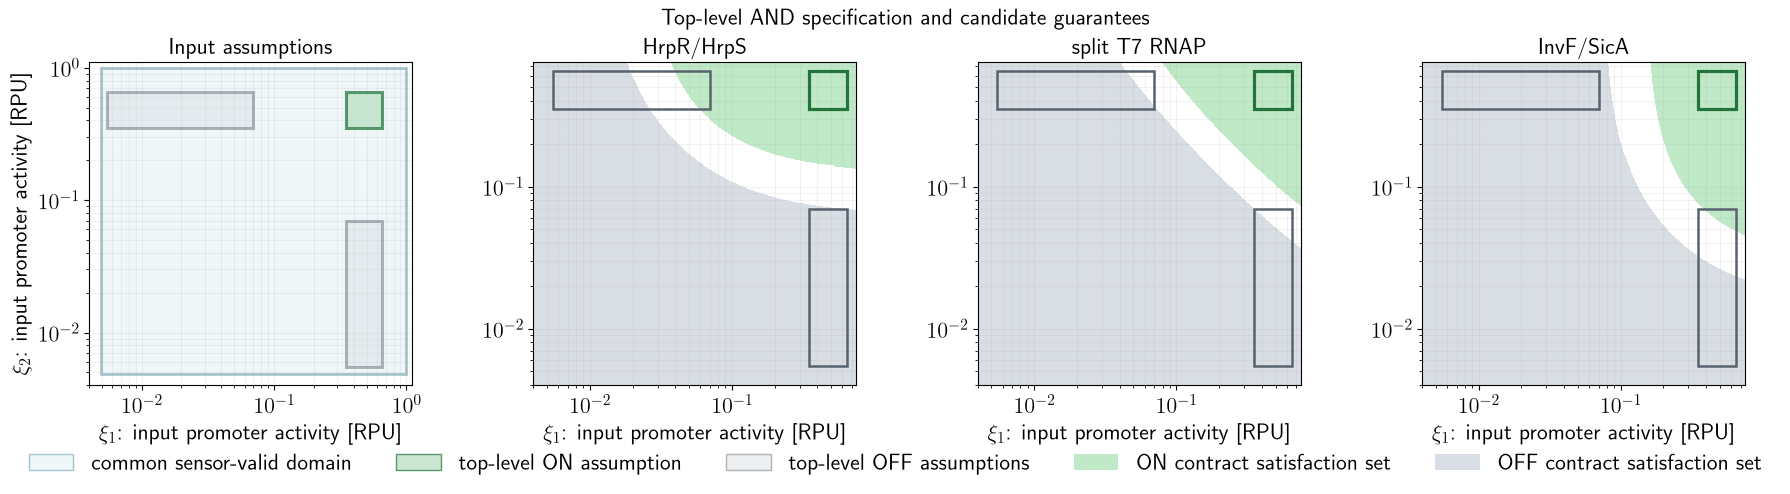

In [24]:
plt.rcParams.update({
    "text.usetex": True,
    "text.latex.preamble": r"\usepackage{amsfonts,amssymb}",
    "font.size": 16,
    "axes.labelsize": 16,
    "axes.titlesize": 16,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "legend.fontsize": 16,
})
on_condition = next(c for c in conditions if c.name == "ON")
off1_condition = next(c for c in conditions if c.name == "OFF-1")
off2_condition = next(c for c in conditions if c.name == "OFF-2")

xi = np.geomspace(0.004, 0.75, 320)
XI1, XI2 = np.meshgrid(xi, xi)

representatives = {}
for candidate in candidates:
    representatives.setdefault(candidate.core.name, candidate)

fig, axes = plt.subplots(1, 4, figsize=(18.0, 4.9), constrained_layout=True)
ax_assume = axes[0]

def add_region(ax, x_bounds, y_bounds, face, edge, label=None, alpha=0.45, lw=2.2, zorder=5):
    patch = Rectangle(
        (x_bounds[0], y_bounds[0]),
        x_bounds[1] - x_bounds[0],
        y_bounds[1] - y_bounds[0],
        facecolor=face,
        edgecolor=edge,
        linewidth=lw,
        alpha=alpha,
        label=label,
        zorder=zorder,
    )
    ax.add_patch(patch)
    return patch

common_sensor_low = max(sensor.leak_rpu for sensor in MARIONETTE_SENSORS.values())
common_sensor_high = min(sensor.linear_max_rpu for sensor in MARIONETTE_SENSORS.values())
add_region(
    ax_assume,
    (common_sensor_low, common_sensor_high),
    (common_sensor_low, common_sensor_high),
    "#d9edf2",
    "#39798a",
    alpha=0.42,
    lw=2.0,
    zorder=1,
)
add_region(
    ax_assume,
    on_condition.xi1_bounds,
    on_condition.xi2_bounds,
    "#b8dfc2",
    "#24733b",
    r"$A_{\mathrm{ON}}$",
    alpha=0.72,
)
add_region(
    ax_assume,
    off1_condition.xi1_bounds,
    off1_condition.xi2_bounds,
    "#d9dde2",
    "#59636e",
    r"$A_{\mathrm{OFF},1}$",
)
add_region(
    ax_assume,
    off2_condition.xi1_bounds,
    off2_condition.xi2_bounds,
    "#d9dde2",
    "#59636e",
)

ax_assume.set_title(r"Input assumptions", fontweight="bold")

for ax, (core_name, candidate) in zip(axes[1:], representatives.items()):
    lower, upper = initial_flux_bounds(candidate, XI1, XI2)
    ax.contourf(
        XI1, XI2, upper <= off1_condition.flux_threshold,
        levels=[0.5, 1.5], colors=["#cfd5dd"], alpha=0.78
    )
    ax.contourf(
        XI1, XI2, lower >= on_condition.flux_threshold,
        levels=[0.5, 1.5], colors=["#79d18b"], alpha=0.48
    )
    add_region(
        ax,
        on_condition.xi1_bounds,
        on_condition.xi2_bounds,
        "none",
        "#24733b",
        alpha=1.0,
        lw=2.3,
    )
    add_region(
        ax,
        off1_condition.xi1_bounds,
        off1_condition.xi2_bounds,
        "none",
        "#59636e",
        alpha=1.0,
        lw=1.8,
    )
    add_region(
        ax,
        off2_condition.xi1_bounds,
        off2_condition.xi2_bounds,
        "none",
        "#59636e",
        alpha=1.0,
        lw=1.8,
    )
    ax.set_title(core_name, fontweight="bold")

for ax in axes:
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(0.004, 0.75)
    ax.set_ylim(0.004, 0.75)
    ax.set_xlabel(r"$\xi_1$: input promoter activity [RPU]")
    ax.grid(which="both", alpha=0.16)
    ax.set_aspect("equal", adjustable="box")
    ax.tick_params(axis="both", which="both", labelsize=16)
axes[0].set_ylabel(r"$\xi_2$: input promoter activity [RPU]")
axes[0].set_xlim(0.004, 1.1)
axes[0].set_ylim(0.004, 1.1)

handles = [
    Patch(facecolor="#d9edf2", edgecolor="#39798a", alpha=0.42,
          label="common sensor-valid domain"),
    Patch(facecolor="#b8dfc2", edgecolor="#24733b", alpha=0.72,
          label="top-level ON assumption"),
    Patch(facecolor="#d9dde2", edgecolor="#59636e", alpha=0.45,
          label="top-level OFF assumptions"),
    Patch(facecolor="#79d18b", edgecolor="none", alpha=0.48,
          label="ON contract satisfaction set"),
    Patch(facecolor="#cfd5dd", edgecolor="none", alpha=0.78,
          label="OFF contract satisfaction set"),
]
fig.legend(
    handles=handles,
    loc="outside lower center",
    ncol=5,
    frameon=False,
)

fig.suptitle("Top-level AND specification and candidate guarantees", fontsize=16, fontweight="bold")
output_base = PAPER_FIGURES_DIR / "compositional_operating_region_summary"
fig.savefig(output_base.with_suffix(".png"), dpi=230, bbox_inches="tight")
fig.savefig(output_base.with_suffix(".pdf"), bbox_inches="tight")
plt.show()

## What the contract contours mean

For each mode $q\in\{\mathrm{ON},\mathrm{OFF\mbox{-}1},\mathrm{OFF\mbox{-}2\}$, the
conditional specification is
\[
\mathcal C_{\rm spec}^q=(A_q,G_q).
\]
Here $A_q$ is a set of allowed input promoter activities and $G_q$ is the
required output-flux inequality for that mode. They are sets in different
spaces, so an assumption is not literally contained in a guarantee. Define the
projected input satisfaction set
\[
S_D^q=\{\xi:\ y_D(\xi;\theta)\text{ satisfies }G_q
\text{ for the fixed parameters of design }D\}.
\]
A design passes mode $q$ when $A_q\subseteq S_D^q$ (every allowed input in
that mode produces only outputs satisfying its output requirement). In the
heatmap, the black outlines mark $A_{\rm ON}$ and the two OFF assumptions.
Green and gray shading mark $S_D^{\rm ON}$ and the common OFF
satisfaction set, respectively. The solid and dashed black contours mark their
boundaries.

## Initial designs and mechanism-specific redesigns

Each column follows one biological architecture from its initial design in the
top row to its mechanism-specific redesign in the bottom row. The outlined ON
and OFF regions are the same fixed top-level requirement in every panel:
$y\ge 120$ nM/min in the ON region and $y\le 60$ nM/min in either OFF region.

Color gives the output flux at the fixed design parameter values.
Gray shading marks the OFF contract satisfaction set. The solid and dashed
black contours show the top-level ON and OFF contract guarantee boundaries.

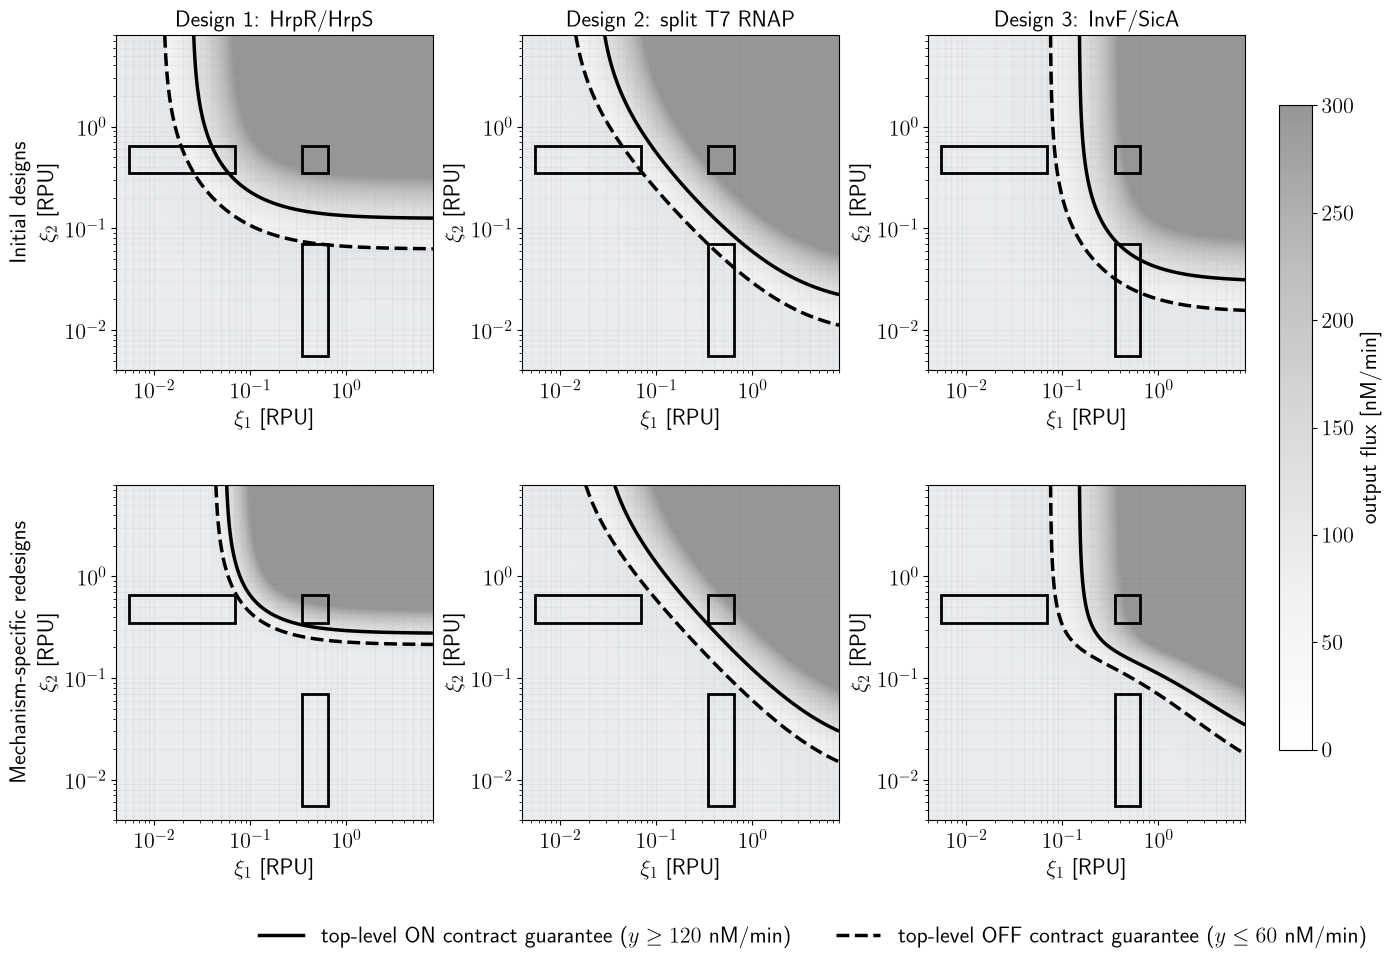

In [25]:
fig, axes = plt.subplots(2, 3, figsize=(16.8, 10.2))
fig.subplots_adjust(
    left=0.075, right=0.89, top=0.94, bottom=0.17,
    wspace=0.28, hspace=0.34,
)

xi_flux = np.geomspace(0.004, 8.0, 500)
XI1_flux, XI2_flux = np.meshgrid(xi_flux, xi_flux)
flux_limits = (xi_flux[0], xi_flux[-1])
vmax = 300.0
flux_cmap = ListedColormap(plt.get_cmap("Greys")(np.linspace(0.0, 0.5, 256)))

def draw_flux_panel(ax, lower, upper, title=None):
    mesh = ax.pcolormesh(
        XI1_flux, XI2_flux, lower,
        shading="auto", cmap=flux_cmap, vmin=0, vmax=vmax,
    )
    off_mask = upper <= off1_condition.flux_threshold
    if np.any(off_mask):
        ax.contourf(
            XI1_flux, XI2_flux, off_mask,
            levels=[0.5, 1.5], colors=["#cfd5dd"], alpha=0.42,
        )
    if np.nanmin(upper) <= off1_condition.flux_threshold <= np.nanmax(upper):
        ax.contour(
            XI1_flux, XI2_flux, upper,
            levels=[off1_condition.flux_threshold], colors=["black"],
            linewidths=2.5, linestyles="dashed", zorder=4,
        )
    if np.nanmin(lower) <= on_condition.flux_threshold <= np.nanmax(lower):
        ax.contour(
            XI1_flux, XI2_flux, lower,
            levels=[on_condition.flux_threshold], colors=["black"],
            linewidths=2.5, linestyles="solid", zorder=4,
        )
    add_region(
        ax, on_condition.xi1_bounds, on_condition.xi2_bounds,
        "none", "black", alpha=1.0, lw=2.0,
    )
    for condition in (off1_condition, off2_condition):
        add_region(
            ax, condition.xi1_bounds, condition.xi2_bounds,
            "none", "black", alpha=1.0, lw=2.0,
        )
    if title:
        ax.set_title(title, fontsize=16, fontweight="bold")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(*flux_limits)
    ax.set_ylim(*flux_limits)
    ax.set_xlabel(r"$\xi_1$ [RPU]")
    ax.set_ylabel(r"$\xi_2$ [RPU]")
    ax.grid(which="both", alpha=0.12)
    ax.tick_params(axis="both", which="both", labelsize=16)
    return mesh

design_titles = {
    "HrpR/HrpS": "Design 1: HrpR/HrpS",
    "split T7 RNAP": "Design 2: split T7 RNAP",
    "InvF/SicA": "Design 3: InvF/SicA",
}

for col, (core_name, candidate) in enumerate(representatives.items()):
    lower, upper = initial_flux_bounds(candidate, XI1_flux, XI2_flux)
    last_mesh = draw_flux_panel(
        axes[0, col], lower, upper, design_titles[core_name]
    )
    lower_new, upper_new = redesigned_flux_bounds(
        candidate, XI1_flux, XI2_flux
    )
    last_mesh = draw_flux_panel(axes[1, col], lower_new, upper_new)

cbar = fig.colorbar(last_mesh, ax=axes.ravel().tolist(), shrink=0.82, pad=0.025)
cbar.solids.set_rasterized(False)
cbar.set_label("output flux [nM/min]")
cbar.ax.tick_params(labelsize=16)

for row, label in enumerate(("Initial designs", "Mechanism-specific redesigns")):
    position = axes[row, 0].get_position()
    fig.text(
        0.018, 0.5 * (position.y0 + position.y1), label,
        rotation=90, va="center", ha="center",
        fontsize=16, fontweight="bold",
    )

legend = [
    Line2D([0], [0], color="black", linewidth=2.5, linestyle="solid",
           label=r"top-level ON contract guarantee ($y\geq120$ nM/min)"),
    Line2D([0], [0], color="black", linewidth=2.5, linestyle="dashed",
           label=r"top-level OFF contract guarantee ($y\leq60$ nM/min)"),
]
fig.legend(
    handles=legend,
    loc="lower center",
    bbox_to_anchor=(0.49, 0.025),
    ncol=2,
    frameon=False,
)

output_base = PAPER_FIGURES_DIR / "compositional_design_flux_maps"
fig.savefig(output_base.with_suffix(".png"), dpi=230, bbox_inches="tight")
fig.savefig(output_base.with_suffix(".pdf"), bbox_inches="tight")
plt.show()

In [26]:
redesign_notes = {
    "Design 1: HrpR/HrpS": (
        r"HrpV inhibition; $V_{\mathrm{eff}}=0.12\,\mu\mathrm{M}$"
    ),
    "Design 2: split T7 RNAP": (
        r"weakened fragment recruitment; $K=3.0\,\mu\mathrm{M}$"
    ),
    "Design 3: InvF/SicA": (
        r"SicA--SipC turnover; $K_{YZ}=28\,\mathrm{nM}$, "
        r"$k_Z=0.1\,\mathrm{min}^{-1}$, with the selected degradation rates"
    ),
}
for design, update in redesign_notes.items():
    print(f"{design}: {update}")

Design 1: HrpR/HrpS: HrpV inhibition; $V_{\mathrm{eff}}=0.12\,\mu\mathrm{M}$
Design 2: split T7 RNAP: weakened fragment recruitment; $K=3.0\,\mu\mathrm{M}$
Design 3: InvF/SicA: SicA--SipC turnover; $K_{YZ}=28\,\mathrm{nM}$, $k_Z=0.1\,\mathrm{min}^{-1}$, with the selected degradation rates


## Interpretation

- The outlined ON/OFF regions and output thresholds are identical in both rows.
- The upper row shows the initial candidates with their provisional uncertainty
  ranges.
- The lower row shows the corresponding updated designs.
- HrpV and split-T7 parameter values are chosen from the contract-feasible
  windows computed above; InvF/SicA uses the selected turnover/degradation
  parameters.
- The shaded regions are the corresponding input-space contract satisfaction sets.